# Bank Marketing: prioritising a limited call list

**Business question.** Given capacity to call only 10% of clients, which clients should the bank contact first to maximise the share who subscribe to a term deposit? The target is `y == "yes"`; the primary measure is Precision@10%, the fraction of subscribers among the highest-scored tenth. The model must rank clients before a call, so `duration` (known only after the call) and `id` cannot be predictors. The analysis below quantifies how much including `duration` would inflate validation results, as a leakage demonstration only.

In [1]:
import sys

import joblib
import numpy as np
import pandas as pd
import sklearn

print(f"Python: {sys.version}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"joblib: {joblib.__version__}")

Python: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
NumPy: 2.3.4
pandas: 2.3.3
scikit-learn: 1.7.2
joblib: 1.5.2


In [2]:
SEED = 2729

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

from sklearn.model_selection import train_test_split

y_train = train["y"].eq("yes").astype(int)
feature_cols = [column for column in train.columns if column not in {"id", "duration", "y"}]
train_features = train.loc[:, feature_cols]
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    train_features,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=SEED,
)

print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")
print(f"Train columns: {train.columns.tolist()}")
print(f"Test columns:  {test.columns.tolist()}")
print(f"Columns present in train but missing from test: {train.columns.difference(test.columns).tolist()}")
development_target_counts = y_dev.value_counts().reindex([0, 1], fill_value=0)
print(f"Development target counts: {{'no': {development_target_counts[0]}, 'yes': {development_target_counts[1]}}} (yes share={y_dev.mean():.4f})")
print(f"Duplicate train id values: {train['id'].duplicated().sum()}")
print(f"Duplicate test id values:  {test['id'].duplicated().sum()}")
print("Business objective: rank clients by likelihood of subscribing and call only the top 10%.")
print("Train has y (the training label) and duration, neither is in test; y is the target, while duration is only known after a call and is therefore excluded to prevent leakage.")
print("id is present for row matching only and is excluded from the predictors.")
print("Precision@10% measures the share of positive responses in the limited call list.")
print(f"Stratified split created before EDA: development={len(X_dev)}, reserved holdout={len(X_holdout)} rows.")
print(f"Observed ID order: train {train['id'].min()}..{train['id'].max()} and test {test['id'].min()}..{test['id'].max()}, each monotonically increasing; id is synthetic and is not a time field.")
print(f"Temporal columns: {[column for column in train.columns if any(token in column.lower() for token in ('date', 'time', 'year'))]}; row order cannot be interpreted as chronology.")

Train shape: (32940, 22)
Test shape:  (8236, 20)
Train columns: ['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
Test columns:  ['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Columns present in train but missing from test: ['duration', 'y']
Development target counts: {'no': 23383, 'yes': 2969} (yes share=0.1127)
Duplicate train id values: 0
Duplicate test id values:  0
Business objective: rank clients by likelihood of subscribing and call only the top 10%.
Train has y (the training label) and duration, neither is in test; y is the target, while duration is only known after a call and is therefore exclude

In [3]:
always_no_predictions = np.zeros(len(y_dev), dtype=int)
print(f"Development majority-class reference accuracy (descriptive only): {(always_no_predictions == y_dev).mean():.4f}")
print("Fold-based baseline comparison is reported with the model CV results below.")

Development majority-class reference accuracy (descriptive only): 0.8873
Fold-based baseline comparison is reported with the model CV results below.


,feature_count,columns
Numeric,8,"age, campaign, previous, emp.var.rate, cons.pr..."
Categorical,11,"job, marital, education, default, housing, loa..."


,unknown_count
job,216
marital,54
education,1138
default,5477
housing,625
loan,625


Literal 'unknown' counts by column: {'job': 216, 'marital': 54, 'education': 1138, 'default': 5477, 'housing': 625, 'loan': 625}
Actual NaN counts in predictors: 0
pdays == 999: 25367 / 26352 rows (0.9626)


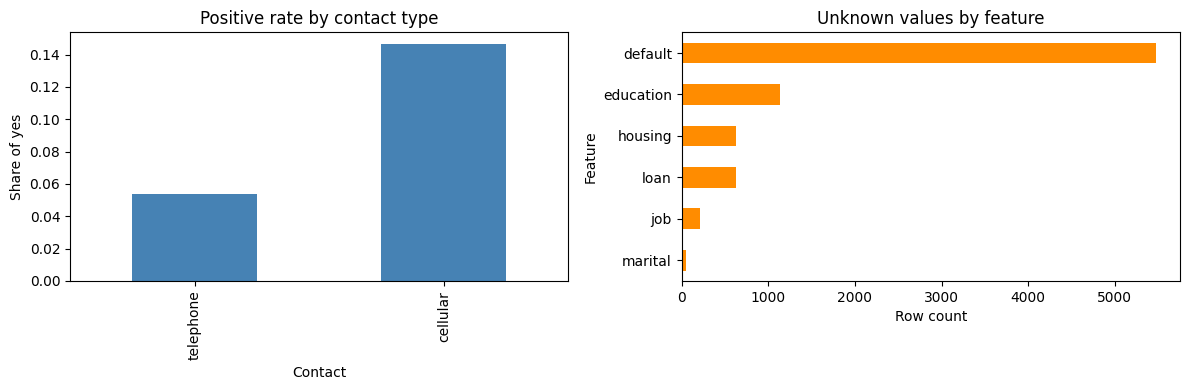

Contact type positive rates: {'telephone': 0.0538, 'cellular': 0.1464}
Largest unknown count: default = 5477


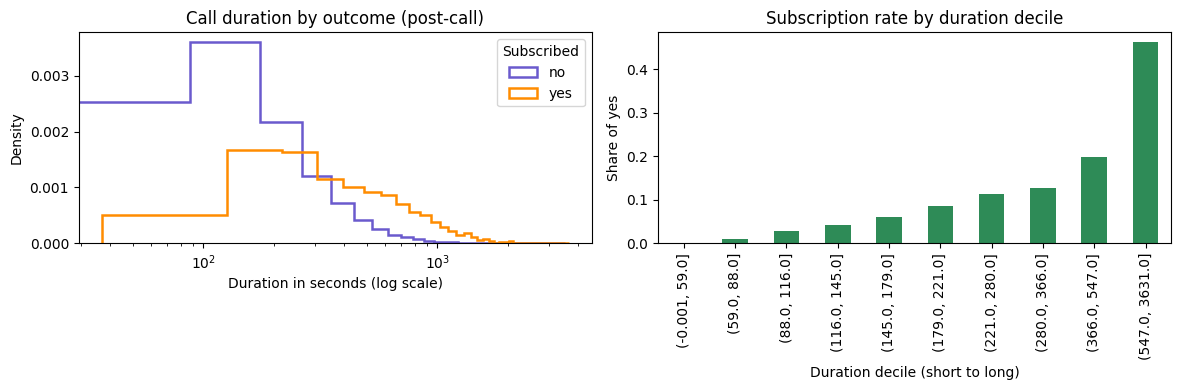

,median,mean
y_binary,,
no,163.0,220.2
yes,450.0,549.8


Duration decile positive rates (shortest to longest): [0.0004, 0.0105, 0.029, 0.0413, 0.0593, 0.0865, 0.1131, 0.1277, 0.1989, 0.4615]
EDA on development only: contact-type positive rates are {'telephone': 0.0538, 'cellular': 0.1464} (association, not causation).
EDA on development only: highest unknown count is default (5477); unknown is retained as a category.
Development pdays=999 count/share: 25367 / 26352 (0.9626); one-hot encoding keeps the sentinel as a separate category.
A random row split may overstate future-campaign performance because train and holdout can share campaign periods and economic conditions; future channel mix, response rates, or macro conditions may shift.
numeric_cols: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
categorical_cols: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'pdays']
pdays is one-hot encoded as a categorical feature;

In [4]:
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline

development_data = train.loc[X_dev.index]
development_features = development_data.loc[:, feature_cols]

numeric_type_cols = [
    column
    for column in development_features.select_dtypes(include=np.number).columns
    if column != "pdays"
]
categorical_cols = development_features.select_dtypes(exclude=np.number).columns.tolist() + ["pdays"]
type_summary = pd.DataFrame(
    {
        "feature_count": [len(numeric_type_cols), len(categorical_cols)],
        "columns": [", ".join(numeric_type_cols), ", ".join(categorical_cols)],
    },
    index=["Numeric", "Categorical"],
)
display(type_summary)

unknown_counts = development_features.eq("unknown").sum()
display(unknown_counts[unknown_counts.gt(0)].rename("unknown_count").to_frame())
missing_counts = development_features.isna().sum()
print(f"Literal 'unknown' counts by column: {unknown_counts[unknown_counts.gt(0)].to_dict()}")
print(f"Actual NaN counts in predictors: {int(missing_counts.sum())}")
pdays_sentinel_share = development_features["pdays"].eq(999).mean()
print(f"pdays == 999: {development_features['pdays'].eq(999).sum()} / {len(development_features)} rows ({pdays_sentinel_share:.4f})")

contact_yes_rate = development_data.assign(y_binary=y_dev).groupby("contact")["y_binary"].mean().sort_values()
unknown_plot_counts = unknown_counts[unknown_counts.gt(0)].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
contact_yes_rate.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Positive rate by contact type", ylabel="Share of yes", xlabel="Contact")
unknown_plot_counts.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set(title="Unknown values by feature", xlabel="Row count", ylabel="Feature")
fig.tight_layout()
plt.show()
print(f"Contact type positive rates: {contact_yes_rate.round(4).to_dict()}")
print(f"Largest unknown count: {unknown_plot_counts.idxmax()} = {unknown_plot_counts.max()}")

# Duration is observed after a call: inspect its target association, but never use it in the deployable model.
duration_by_target = development_data.assign(y_binary=y_dev).groupby("y_binary")["duration"].agg(["median", "mean"])
duration_decile = pd.qcut(development_data["duration"], q=10, duplicates="drop")
duration_response = development_data.assign(y_binary=y_dev, duration_decile=duration_decile).groupby(
    "duration_decile", observed=True
)["y_binary"].agg(["mean", "count"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for target, label, color in [(0, "no", "slateblue"), (1, "yes", "darkorange")]:
    axes[0].hist(
        development_data.loc[y_dev.eq(target), "duration"],
        bins=40,
        density=True,
        histtype="step",
        linewidth=1.8,
        label=label,
        color=color,
    )
axes[0].set_xscale("log")
axes[0].set(title="Call duration by outcome (post-call)", xlabel="Duration in seconds (log scale)", ylabel="Density")
axes[0].legend(title="Subscribed")
duration_response["mean"].plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set(title="Subscription rate by duration decile", xlabel="Duration decile (short to long)", ylabel="Share of yes")
fig.tight_layout()
plt.show()
display(duration_by_target.rename(index={0: "no", 1: "yes"}).round(1))
print(f"Duration decile positive rates (shortest to longest): {duration_response['mean'].round(4).tolist()}")
print(f"EDA on development only: contact-type positive rates are {contact_yes_rate.round(4).to_dict()} (association, not causation).")
print(f"EDA on development only: highest unknown count is {unknown_plot_counts.idxmax()} ({unknown_plot_counts.max()}); unknown is retained as a category.")
print(f"Development pdays=999 count/share: {development_features['pdays'].eq(999).sum()} / {len(development_features)} ({pdays_sentinel_share:.4f}); one-hot encoding keeps the sentinel as a separate category.")
print("A random row split may overstate future-campaign performance because train and holdout can share campaign periods and economic conditions; future channel mix, response rates, or macro conditions may shift.")

# Treat pdays as a category so its 999 sentinel is not interpreted as a numeric value.
numeric_cols = numeric_type_cols
print(f"numeric_cols: {numeric_cols}")
print(f"categorical_cols: {categorical_cols}")

print("pdays is one-hot encoded as a categorical feature; the 999 sentinel is retained as its own category.")

In [5]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def precision_at_fraction(y_true, y_score, fraction=0.1):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    if y_score.ndim == 2:
        y_score = y_score[:, 1]
    n_selected = max(1, int(np.ceil(len(y_true) * fraction)))
    top_indices = np.argsort(-y_score, kind="stable")[:n_selected]
    return float(y_true[top_indices].mean())

numeric_preprocessing = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_preprocessing = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_preprocessing, numeric_cols),
        ("categorical", categorical_preprocessing, categorical_cols),
    ]
)

logistic_pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                random_state=SEED,
            ),
        ),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "precision_at_10_percent": make_scorer(
        precision_at_fraction,
        response_method="predict_proba",
        fraction=0.1,
    ),
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "accuracy": "accuracy",
}
cv_results = cross_validate(
    logistic_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1,
)

cv_summary = pd.DataFrame(
    {
        "metric": ["Precision@10% (primary)", "ROC AUC", "Average precision (PR AUC)"],
        "mean": [
            cv_results["test_precision_at_10_percent"].mean(),
            cv_results["test_roc_auc"].mean(),
            cv_results["test_average_precision"].mean(),
        ],
        "std": [
            cv_results["test_precision_at_10_percent"].std(ddof=1),
            cv_results["test_roc_auc"].std(ddof=1),
            cv_results["test_average_precision"].std(ddof=1),
        ],
    }
)
cv_summary["mean ± std"] = cv_summary.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
)
display(cv_summary[["metric", "mean ± std"]])

# Leakage diagnostic only: quantify the optimistic CV gain from a field known only after the call.
duration_preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_preprocessing, numeric_cols + ["duration"]),
        ("categorical", categorical_preprocessing, categorical_cols),
    ]
)
duration_diagnostic_pipeline = clone(logistic_pipeline).set_params(
    preprocessor=duration_preprocessor
)
X_dev_with_duration = train.loc[X_dev.index, feature_cols + ["duration"]]
duration_cv_results = cross_validate(
    duration_diagnostic_pipeline,
    X_dev_with_duration,
    y_dev,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1,
)
duration_leakage_comparison = pd.DataFrame(
    {
        "without duration": [
            f"{cv_results['test_precision_at_10_percent'].mean():.4f} ± {cv_results['test_precision_at_10_percent'].std(ddof=1):.4f}",
            f"{cv_results['test_roc_auc'].mean():.4f} ± {cv_results['test_roc_auc'].std(ddof=1):.4f}",
        ],
        "with duration (leakage diagnostic)": [
            f"{duration_cv_results['test_precision_at_10_percent'].mean():.4f} ± {duration_cv_results['test_precision_at_10_percent'].std(ddof=1):.4f}",
            f"{duration_cv_results['test_roc_auc'].mean():.4f} ± {duration_cv_results['test_roc_auc'].std(ddof=1):.4f}",
        ],
    },
    index=["Precision@10%", "ROC AUC"],
)
display(duration_leakage_comparison)
print("With-duration CV is a leakage diagnostic only: call duration is unavailable when the call list is made.")

,metric,mean ± std
0,Precision@10% (primary),0.4880 ± 0.0236
1,ROC AUC,0.7890 ± 0.0084
2,Average precision (PR AUC),0.4372 ± 0.0175


,without duration,with duration (leakage diagnostic)
Precision@10%,0.4880 ± 0.0236,0.6086 ± 0.0202
ROC AUC,0.7890 ± 0.0084,0.9363 ± 0.0043


With-duration CV is a leakage diagnostic only: call duration is unavailable when the call list is made.


,value
OOF diagnostic cutoff (not final),0.7865
Precision@10% (primary),0.4894
Recall at 10% capacity,0.4345
Share selected,0.1000
OOF average precision,0.4344


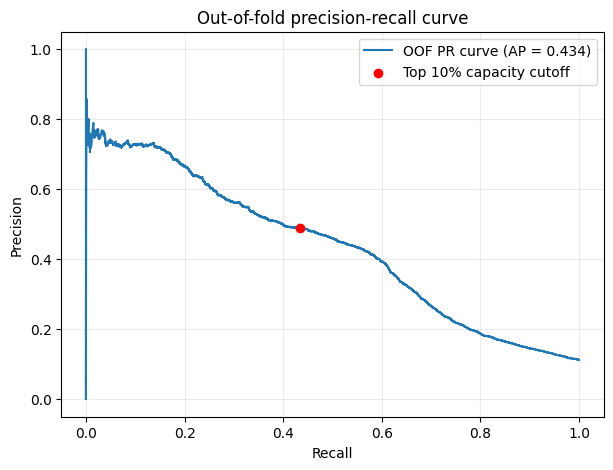

In [6]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    logistic_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_dev,
    oof_probabilities,
)

capacity = 0.10
n_to_call = int(np.ceil(capacity * len(y_dev)))
top_indices = np.argsort(-oof_probabilities, kind="stable")[:n_to_call]
oof_diagnostic_threshold = oof_probabilities[top_indices[-1]]
oof_predictions = np.zeros(len(y_dev), dtype=int)
oof_predictions[top_indices] = 1

precision_at_10 = y_dev.iloc[top_indices].mean()
recall_at_10 = precision_at_10 * n_to_call / y_dev.sum()
oof_average_precision = average_precision_score(y_dev, oof_probabilities)

threshold_results = pd.DataFrame(
    {
        "value": [
            oof_diagnostic_threshold,
            precision_at_10,
            recall_at_10,
            n_to_call / len(y_dev),
            oof_average_precision,
        ]
    },
    index=[
        "OOF diagnostic cutoff (not final)",
        "Precision@10% (primary)",
        "Recall at 10% capacity",
        "Share selected",
        "OOF average precision",
    ],
)
display(threshold_results.round(4))

plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label=f"OOF PR curve (AP = {oof_average_precision:.3f})")
plt.scatter(
    [recall_at_10],
    [precision_at_10],
    color="red",
    zorder=3,
    label="Top 10% capacity cutoff",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-fold precision-recall curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [7]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

random_forest_pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(n_estimators=60, random_state=SEED, n_jobs=-1),
        ),
    ]
)
decision_tree_pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
        ),
    ]
)

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
def make_search(estimator, param_grid):
    return GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring=scoring["precision_at_10_percent"],
        cv=inner_cv,
        refit=True,
        n_jobs=1,
    )

model_candidates = {
    "Majority baseline (prior)": DummyClassifier(strategy="prior", random_state=SEED),
    "Logistic regression (balanced)": make_search(logistic_pipeline, {"classifier__C": [0.1, 1.0, 10.0]}),
    "Logistic regression (no class weights)": make_search(
        clone(logistic_pipeline).set_params(classifier__class_weight=None),
        {"classifier__C": [0.1, 1.0, 10.0]},
    ),
    "Decision tree (balanced)": make_search(
        decision_tree_pipeline,
        {"classifier__max_depth": [6, 10, None], "classifier__min_samples_leaf": [5]},
    ),
    "Random forest (no class weights)": make_search(
        clone(random_forest_pipeline).set_params(classifier__class_weight=None),
        {"classifier__min_samples_leaf": [3, 5, 10]},
    ),
    "Random forest (balanced)": make_search(
        clone(random_forest_pipeline).set_params(classifier__class_weight="balanced"),
        {"classifier__min_samples_leaf": [3, 5, 10]},
    ),
}
model_cv_results = {}
for model_name, estimator in model_candidates.items():
    model_cv_results[model_name] = cross_validate(
        estimator,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
    )

comparison_rows = []
metric_columns = [
    ("Precision@10%", "test_precision_at_10_percent"),
    ("ROC AUC", "test_roc_auc"),
    ("Average precision", "test_average_precision"),
    ("Accuracy", "test_accuracy"),
]
for model_name, results in model_cv_results.items():
    for metric_name, score_key in metric_columns:
        fold_scores = results[score_key]
        comparison_rows.append(
            {
                "model": model_name,
                "metric": metric_name,
                "mean ± std": f"{fold_scores.mean():.4f} ± {fold_scores.std(ddof=1):.4f}",
            }
        )

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.pivot(index="model", columns="metric", values="mean ± std"))
print("All models use the same five outer folds; search grids are evaluated only inside each outer training fold.")
prior_cv = model_cv_results["Majority baseline (prior)"]
print(f"Majority baseline: accuracy={prior_cv['test_accuracy'].mean():.4f} ± {prior_cv['test_accuracy'].std(ddof=1):.4f}, but Precision@10%={prior_cv['test_precision_at_10_percent'].mean():.4f} ± {prior_cv['test_precision_at_10_percent'].std(ddof=1):.4f}; accuracy alone hides poor call-list ranking.")
print("The prior baseline's Precision@10% is the explicit minimum bar for every candidate; tied scores make its top-decile result only a tie-order reference.")
baseline_mean = prior_cv["test_precision_at_10_percent"].mean()
baseline_std = prior_cv["test_precision_at_10_percent"].std(ddof=1)
for candidate_name, candidate_results in model_cv_results.items():
    if candidate_name == "Majority baseline (prior)":
        continue
    candidate_scores = candidate_results["test_precision_at_10_percent"]
    print(
        f"{candidate_name} vs baseline Precision@10% bar: "
        f"{candidate_scores.mean():.4f} ± {candidate_scores.std(ddof=1):.4f} "
        f"vs {baseline_mean:.4f} ± {baseline_std:.4f}."
    )

unknown_missing_pipeline = clone(logistic_pipeline).set_params(
    preprocessor__categorical__imputer=SimpleImputer(
        missing_values="unknown",
        strategy="most_frequent",
    )
)
unknown_handling_results = cross_validate(
    logistic_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    scoring=scoring["precision_at_10_percent"],
    n_jobs=1,
)
unknown_as_missing_results = cross_validate(
    unknown_missing_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    scoring=scoring["precision_at_10_percent"],
    n_jobs=1,
)
unknown_handling_comparison = pd.DataFrame(
    {
        "mean ± std": [
            f"{unknown_handling_results['test_score'].mean():.4f} ± {unknown_handling_results['test_score'].std(ddof=1):.4f}",
            f"{unknown_as_missing_results['test_score'].mean():.4f} ± {unknown_as_missing_results['test_score'].std(ddof=1):.4f}",
        ]
    },
    index=["unknown kept as category", "unknown imputed to most frequent"],
)
display(unknown_handling_comparison)

unknown_mean_gap = abs(unknown_handling_results['test_score'].mean() - unknown_as_missing_results['test_score'].mean())
unknown_combined_spread = np.sqrt(unknown_handling_results['test_score'].std(ddof=1) ** 2 + unknown_as_missing_results['test_score'].std(ddof=1) ** 2)
print(f"Preprocessing comparison: mean gap={unknown_mean_gap:.4f}, combined fold spread={unknown_combined_spread:.4f}; no evidence of a meaningful difference, so retain unknown as its own potentially informative category.")
print("pdays=999 means no prior contact; keeping it categorical avoids treating 999 as a numeric distance. The separate was_contacted flag was omitted because it duplicates this one-hot category.")

rf_weighted = model_cv_results["Random forest (balanced)"]["test_precision_at_10_percent"]
rf_unweighted = model_cv_results["Random forest (no class weights)"]["test_precision_at_10_percent"]
print(f"Random forest class-weight comparison, Precision@10%: balanced={rf_weighted.mean():.4f} ± {rf_weighted.std(ddof=1):.4f}; no weights={rf_unweighted.mean():.4f} ± {rf_unweighted.std(ddof=1):.4f}")
lr_scores = model_cv_results["Logistic regression (balanced)"]["test_precision_at_10_percent"]
rf_balanced_mean = rf_weighted.mean()
rf_vs_lr_gap = rf_balanced_mean - lr_scores.mean()
combined_fold_spread = np.sqrt(rf_weighted.std(ddof=1) ** 2 + lr_scores.std(ddof=1) ** 2)
print(f"Random forest minus logistic Precision@10% gap={rf_vs_lr_gap:.4f}; combined fold spread={combined_fold_spread:.4f}.")
weight_gap = rf_weighted.mean() - rf_unweighted.mean()
weight_spread = np.sqrt(rf_weighted.std(ddof=1) ** 2 + rf_unweighted.std(ddof=1) ** 2)
print(f"Class-weight effect: balanced minus unweighted Precision@10%={weight_gap:.4f}, combined fold spread={weight_spread:.4f}; the difference is small relative to fold variability.")
print("No robust winner: the top Random Forest minus balanced Logistic Regression Precision@10% gain is smaller than their combined fold spread. Select logistic regression for simplicity, not because the observed ranking difference establishes superiority.")

metric,Accuracy,Average precision,Precision@10%,ROC AUC
model,,,,
Decision tree (balanced),0.8394 ± 0.0229,0.4132 ± 0.0176,0.4945 ± 0.0152,0.7805 ± 0.0082
Logistic regression (balanced),0.8288 ± 0.0109,0.4362 ± 0.0177,0.4877 ± 0.0240,0.7889 ± 0.0085
Logistic regression (no class weights),0.8987 ± 0.0030,0.4389 ± 0.0167,0.4907 ± 0.0154,0.7891 ± 0.0088
Majority baseline (prior),0.8873 ± 0.0001,0.1127 ± 0.0001,0.1069 ± 0.0075,0.5000 ± 0.0000
Random forest (balanced),0.8654 ± 0.0041,0.4530 ± 0.0214,0.4994 ± 0.0188,0.7914 ± 0.0110
Random forest (no class weights),0.8986 ± 0.0022,0.4547 ± 0.0129,0.5040 ± 0.0166,0.7874 ± 0.0059


All models use the same five outer folds; search grids are evaluated only inside each outer training fold.
Majority baseline: accuracy=0.8873 ± 0.0001, but Precision@10%=0.1069 ± 0.0075; accuracy alone hides poor call-list ranking.
The prior baseline's Precision@10% is the explicit minimum bar for every candidate; tied scores make its top-decile result only a tie-order reference.
Logistic regression (balanced) vs baseline Precision@10% bar: 0.4877 ± 0.0240 vs 0.1069 ± 0.0075.
Logistic regression (no class weights) vs baseline Precision@10% bar: 0.4907 ± 0.0154 vs 0.1069 ± 0.0075.
Decision tree (balanced) vs baseline Precision@10% bar: 0.4945 ± 0.0152 vs 0.1069 ± 0.0075.
Random forest (no class weights) vs baseline Precision@10% bar: 0.5040 ± 0.0166 vs 0.1069 ± 0.0075.
Random forest (balanced) vs baseline Precision@10% bar: 0.4994 ± 0.0188 vs 0.1069 ± 0.0075.


,mean ± std
unknown kept as category,0.4880 ± 0.0236
unknown imputed to most frequent,0.4888 ± 0.0235


Preprocessing comparison: mean gap=0.0008, combined fold spread=0.0333; no evidence of a meaningful difference, so retain unknown as its own potentially informative category.
pdays=999 means no prior contact; keeping it categorical avoids treating 999 as a numeric distance. The separate was_contacted flag was omitted because it duplicates this one-hot category.
Random forest class-weight comparison, Precision@10%: balanced=0.4994 ± 0.0188; no weights=0.5040 ± 0.0166
Random forest minus logistic Precision@10% gap=0.0118; combined fold spread=0.0305.
Class-weight effect: balanced minus unweighted Precision@10%=-0.0045, combined fold spread=0.0251; the difference is small relative to fold variability.
No robust winner: the top Random Forest minus balanced Logistic Regression Precision@10% gain is smaller than their combined fold spread. Select logistic regression for simplicity, not because the observed ranking difference establishes superiority.


Highest CV mean: Random forest (no class weights); selected model: Logistic regression (balanced).
The simpler logistic model is preferred when its difference from the top mean is within combined fold spread.


Selected model: Logistic regression (balanced)
Selected parameters from development CV: {'classifier__C': 1.0}


,value
Holdout ROC AUC,0.8036
Holdout average precision,0.4884
10% capacity threshold,0.7851
Precision@10%,0.5341
Recall@10%,0.4744
Lift vs random calls,4.7425


Confusion matrix [rows=true 0/1, columns=predicted 0/1]:
[[5539  307]
 [ 390  352]]
At 10% capacity: 352 yes clients reached; 390 yes clients not reached.
Of the 659 attempted holdout calls, 307 did not result in a subscription (false-positive calls).
Holdout interpretation: the call list captures 53.4% positive responses versus 11.3% prevalence (4.74x lift); it finds 352 positives and misses 390.
The holdout result is one estimate, not a guarantee: a random split can share campaign-time and macroeconomic patterns with training, unlike a true train-on-past/test-on-future deployment.


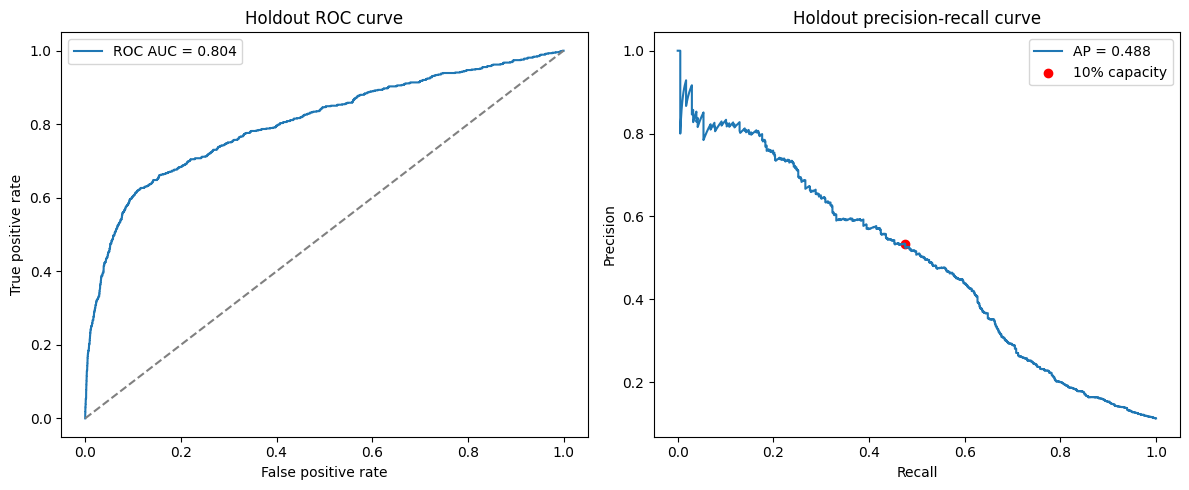

In [8]:
ranked_models = sorted(
    [name for name in model_candidates if name != "Majority baseline (prior)"],
    key=lambda name: model_cv_results[name]["test_precision_at_10_percent"].mean(),
    reverse=True,
)
best_model_name = ranked_models[0]
best_scores = model_cv_results[best_model_name]["test_precision_at_10_percent"]
logistic_scores = model_cv_results["Logistic regression (balanced)"]["test_precision_at_10_percent"]
best_vs_logistic_gap = best_scores.mean() - logistic_scores.mean()
best_vs_logistic_spread = np.sqrt(best_scores.std(ddof=1) ** 2 + logistic_scores.std(ddof=1) ** 2)
selected_model_name = (
    "Logistic regression (balanced)"
    if best_model_name != "Logistic regression (balanced)" and best_vs_logistic_gap <= best_vs_logistic_spread
    else best_model_name
)
print(f"Highest CV mean: {best_model_name}; selected model: {selected_model_name}.")
print("The simpler logistic model is preferred when its difference from the top mean is within combined fold spread.")
selected_search = model_candidates[selected_model_name]
selected_search.fit(X_dev, y_dev)
selected_pipeline = selected_search.best_estimator_
print(f"Selected model: {selected_model_name}")
print(f"Selected parameters from development CV: {selected_search.best_params_}")

holdout_scores = selected_pipeline.predict_proba(X_holdout)[:, 1]
holdout_roc_auc = roc_auc_score(y_holdout, holdout_scores)
holdout_average_precision = average_precision_score(y_holdout, holdout_scores)
holdout_pr_precision, holdout_pr_recall, _ = precision_recall_curve(y_holdout, holdout_scores)
holdout_fpr, holdout_tpr, _ = roc_curve(y_holdout, holdout_scores)

n_holdout_calls = int(np.ceil(capacity * len(y_holdout)))
holdout_top_indices = np.argsort(-holdout_scores, kind="stable")[:n_holdout_calls]
decision_threshold = holdout_scores[holdout_top_indices[-1]]
holdout_predictions = np.zeros(len(y_holdout), dtype=int)
holdout_predictions[holdout_top_indices] = 1
holdout_precision_at_10 = y_holdout.iloc[holdout_top_indices].mean()
holdout_recall_at_10 = holdout_precision_at_10 * n_holdout_calls / y_holdout.sum()
holdout_prevalence = y_holdout.mean()
holdout_lift = holdout_precision_at_10 / holdout_prevalence
holdout_confusion_matrix = confusion_matrix(y_holdout, holdout_predictions, labels=[0, 1])

final_evaluation = pd.DataFrame(
    {"value": [holdout_roc_auc, holdout_average_precision, decision_threshold, holdout_precision_at_10, holdout_recall_at_10, holdout_lift]},
    index=["Holdout ROC AUC", "Holdout average precision", "10% capacity threshold", "Precision@10%", "Recall@10%", "Lift vs random calls"],
)
display(final_evaluation.round(4))
print("Confusion matrix [rows=true 0/1, columns=predicted 0/1]:")
print(holdout_confusion_matrix)
print(f"At 10% capacity: {holdout_confusion_matrix[1, 1]} yes clients reached; {holdout_confusion_matrix[1, 0]} yes clients not reached.")
print(f"Of the {int(holdout_predictions.sum())} attempted holdout calls, {holdout_confusion_matrix[0, 1]} did not result in a subscription (false-positive calls).")
print(f"Holdout interpretation: the call list captures {holdout_precision_at_10:.1%} positive responses versus {holdout_prevalence:.1%} prevalence ({holdout_lift:.2f}x lift); it finds {holdout_confusion_matrix[1, 1]} positives and misses {holdout_confusion_matrix[1, 0]}.")
print("The holdout result is one estimate, not a guarantee: a random split can share campaign-time and macroeconomic patterns with training, unlike a true train-on-past/test-on-future deployment.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(holdout_fpr, holdout_tpr, label=f"ROC AUC = {holdout_roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(title="Holdout ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()
axes[1].plot(holdout_pr_recall, holdout_pr_precision, label=f"AP = {holdout_average_precision:.3f}")
axes[1].scatter([holdout_recall_at_10], [holdout_precision_at_10], color="red", label="10% capacity")
axes[1].set(title="Holdout precision-recall curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()
fig.tight_layout()
plt.show()

In [9]:
final_pipeline = clone(selected_pipeline)
final_pipeline.fit(train_features, y_train)
joblib.dump(final_pipeline, "model.joblib")

print(f"Refit selected pipeline on all train rows and saved model.joblib ({selected_model_name}).")

Refit selected pipeline on all train rows and saved model.joblib (Logistic regression (balanced)).


In [10]:
loaded_pipeline = joblib.load("model.joblib")
test_features = test
prediction_check_features = train_features.iloc[:20]
in_memory_check_scores = final_pipeline.predict_proba(prediction_check_features)[:, 1]
loaded_check_scores = loaded_pipeline.predict_proba(prediction_check_features)[:, 1]
np.testing.assert_allclose(loaded_check_scores, in_memory_check_scores, rtol=1e-12, atol=1e-12)
loaded_test_scores = loaded_pipeline.predict_proba(test_features)[:, 1]
print("The saved pipeline scores the unmodified test.csv DataFrame; ColumnTransformer selects predictors and ignores id.")

n_test_calls = int(np.ceil(capacity * len(test)))
test_top_indices = np.argsort(-loaded_test_scores, kind="stable")[:n_test_calls]
test_predictions = np.zeros(len(test), dtype=int)
test_predictions[test_top_indices] = 1
predictions = pd.DataFrame(
    {
        "id": test["id"],
        "y_pred": test_predictions,
        "y_score": loaded_test_scores,
    }
)
predictions.to_csv("predictions.csv", index=False)

print(f"Reloaded pipeline matches in-memory predictions on a train sample: {np.allclose(loaded_check_scores, in_memory_check_scores, rtol=1e-12, atol=1e-12)}")
print(f"Predictions shape: {predictions.shape}")
print(f"Prediction columns: {predictions.columns.tolist()}")
print(f"Predicted yes count (top 10%): {int(predictions['y_pred'].sum())} / {len(predictions)}")
print(f"Share predicted yes: {predictions['y_pred'].mean():.4f}")

The saved pipeline scores the unmodified test.csv DataFrame; ColumnTransformer selects predictors and ignores id.
Reloaded pipeline matches in-memory predictions on a train sample: True
Predictions shape: (8236, 3)
Prediction columns: ['id', 'y_pred', 'y_score']
Predicted yes count (top 10%): 824 / 8236
Share predicted yes: 0.1000
